<a href="https://colab.research.google.com/github/TebogoLesedi1/data_science_pratice/blob/main/pratice2_b.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


import all the needed libraries

In [34]:
#import pandas, numpy, matplotlib, preprocessing and others models
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier



In [35]:
#create a dataframe
df = pd.read_csv("/content/drive/MyDrive/MELBOURNE_HOUSE_PRICES_LESS.csv")

In [36]:
#check the number of rows and columns
df.shape

(63023, 13)

In [37]:
#check column names
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 63023 entries, 0 to 63022
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Suburb         63023 non-null  object 
 1   Address        63023 non-null  object 
 2   Rooms          63023 non-null  int64  
 3   Type           63023 non-null  object 
 4   Price          48433 non-null  float64
 5   Method         63023 non-null  object 
 6   SellerG        63023 non-null  object 
 7   Date           63023 non-null  object 
 8   Postcode       63023 non-null  int64  
 9   Regionname     63023 non-null  object 
 10  Propertycount  63023 non-null  int64  
 11  Distance       63023 non-null  float64
 12  CouncilArea    63023 non-null  object 
dtypes: float64(2), int64(3), object(8)
memory usage: 6.3+ MB


In [38]:
#check the statistical summary
df.describe()

,Rooms,Price,Postcode,Propertycount,Distance
count,63023.000000,4.843300e+04,63023.000000,63023.000000,63023.000000
mean,3.110595,9.978982e+05,3125.673897,7617.728131,12.684829
std,0.957551,5.934989e+05,125.626877,4424.423167,7.592015
min,1.000000,8.500000e+04,3000.000000,39.000000,0.000000
25%,3.000000,6.200000e+05,3056.000000,4380.000000,7.000000
50%,3.000000,8.300000e+05,3107.000000,6795.000000,11.400000
75%,4.000000,1.220000e+06,3163.000000,10412.000000,16.700000
max,31.000000,1.120000e+07,3980.000000,21650.000000,64.100000


In [39]:
#check null values or missing values
df.isnull().sum()

,0
Suburb,0
Address,0
Rooms,0
Type,0
Price,14590
Method,0
SellerG,0
Date,0
Postcode,0
Regionname,0


In [41]:
#remove null values or missing values
df = df.dropna()

In [42]:
#check null values or missing values
df.isnull().sum()

,0
Suburb,0
Address,0
Rooms,0
Type,0
Price,0
Method,0
SellerG,0
Date,0
Postcode,0
Regionname,0


In [43]:
#check for duplicates
df.duplicated().sum()

np.int64(1)

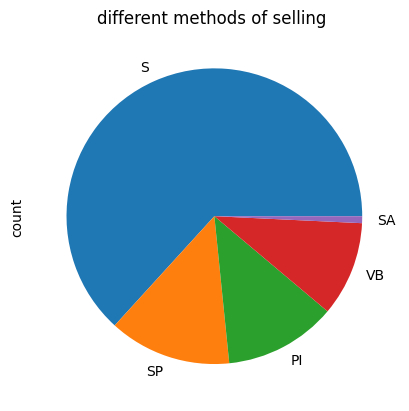

In [46]:
#visualize the data (method) wirh a pie chart
method = df["Method"].value_counts()
method.plot.pie()
plt.title("different methods of selling ")
plt.show()

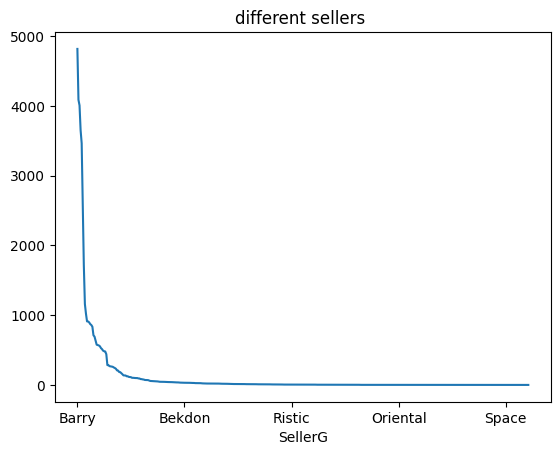

In [47]:
#visuailze using a line chart for selling groups
method = df["SellerG"].value_counts()
method.plot.line()
plt.title("different sellers ")
plt.show()

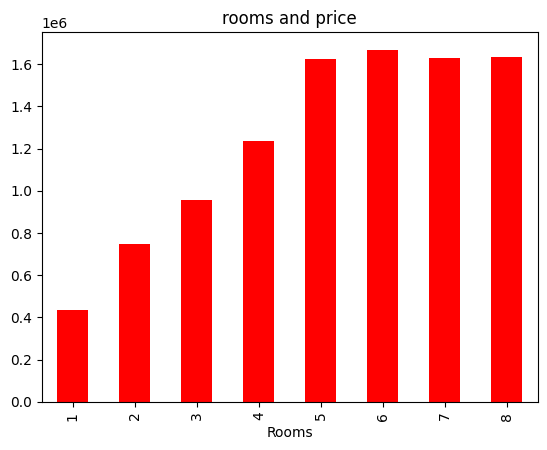

In [56]:
#bar chart for rooms and price using mean
rooms = df[df["Rooms"] <= 8].groupby("Rooms")["Price"].mean()
rooms.plot.bar(color= "red")
plt.title("rooms and price")
plt.show()


In [60]:
from sklearn.preprocessing import LabelEncoder

# Clean column names by removing leading/trailing whitespaces
df.columns = df.columns.str.strip()

# Identify all categorical (object) columns
categorical_cols = df.select_dtypes(include=["object"]).columns

# Loop through and encode each categorical column
label_encoders = {}
for col in categorical_cols:
    le = LabelEncoder()
    # Convert to string first to handle any mixed data types or NaNs smoothly
    df[col] = le.fit_transform(df[col].astype(str))
    # Store the encoder if you need to inverse_transform later
    label_encoders[col] = le


In [61]:
#define the x(feature or predictor) and y(dependent)
x = df.drop("Price", axis = 1)
y = df["Price"]

In [62]:
#slipt the data into training and testing data
X_train, X_test, y_train,y_test = train_test_split(
x,
y,
test_size = 0.2,
random_state = 42)

In [ ]:
#create models
model_lr = LogisticRegression()
model_lr.fit(X_train,y_train)

In [59]:
# Generate predictions Use the test data to predict
y_pred =model_lr.predict(X_test)

ValueError: could not convert string to float: 'Dingley Village'

3.9 Evaluate the model (3) Calculate:

Accuracy;

Confusion matrix;

Classification report.

In [58]:
#import the metrics
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [ ]:
accuracy = accuracy_score(y_yest, y_pred)
print("Accuracy:", accuracy)

In [ ]:
confusion_matrix = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:")
print(confusion_matrix)

In [ ]:
classification_report = classification_report(y_test, y_pred)
print("Classification Report:")
print(classification_report)